# 03. Baseline Forecasts: Models, Metrics, and Results

**Block 3 of the project.** This notebook answers one question: *how well do simple, non-ML forecasting methods predict the next 12 months of six official Ukrainian average prices, and which of them is worth carrying forward?*

It reads the rolling-origin backtest written by `src/forecasting/no_ml_predictions_v4.py` (run it first; about 20 seconds). The final section also refits every model on all data through June 2025 and checks it against July–September 2025, which were published after our data snapshot (`src/data/prepare_holdout.py`).

In [1]:
import sys
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "results").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Could not find the project root containing results/")
sys.path.insert(0, str(ROOT / "src"))
from forecasting import no_ml_predictions_v4 as bt
from reporting import style
style.apply()

RESULTS = ROOT / "results"
files = {"backtest": RESULTS / "backtest_results.csv",
         "convergence": RESULTS / "sarima_convergence.csv",
         "fallbacks": RESULTS / "fallbacks.csv"}
missing = [str(path) for path in files.values() if not path.exists()]
if missing:
    raise FileNotFoundError("Missing result files: " + ", ".join(missing)
                            + ". Run src/forecasting/no_ml_predictions_v4.py first.")
backtest = pd.read_csv(files["backtest"], parse_dates=["origin", "date"])
convergence = pd.read_csv(files["convergence"], parse_dates=["origin"])
fallbacks = pd.read_csv(files["fallbacks"], parse_dates=["origin"])
backtest["product"] = backtest["good"].map(style.LABELS)
MODELS = bt.ORDER
PRODUCTS = list(style.LABELS.values())
print(f"Forecast rows: {len(backtest):,} = {backtest['product'].nunique()} products x "
      f"{backtest['model'].nunique()} models x {backtest['origin'].nunique()} origins x {backtest['h'].max()} horizons")

Forecast rows: 5,040 = 6 products x 7 models x 10 origins x 12 horizons


## 1. How These Scores Were Produced (recap of Block 2)

Expanding-window rolling origin: the first model sees 36 months (2017-01 to 2019-12) and forecasts the next 12; the origin then moves 6 months forward and the training window grows. Every model, transformation, and the MASE scale are fitted on the training window only, so no test month leaks into a forecast. The 12-month horizon matches a yearly procurement-planning cycle.

Three test windows end before 2022, one straddles February 2022, and six start after it; results are also reported per regime.

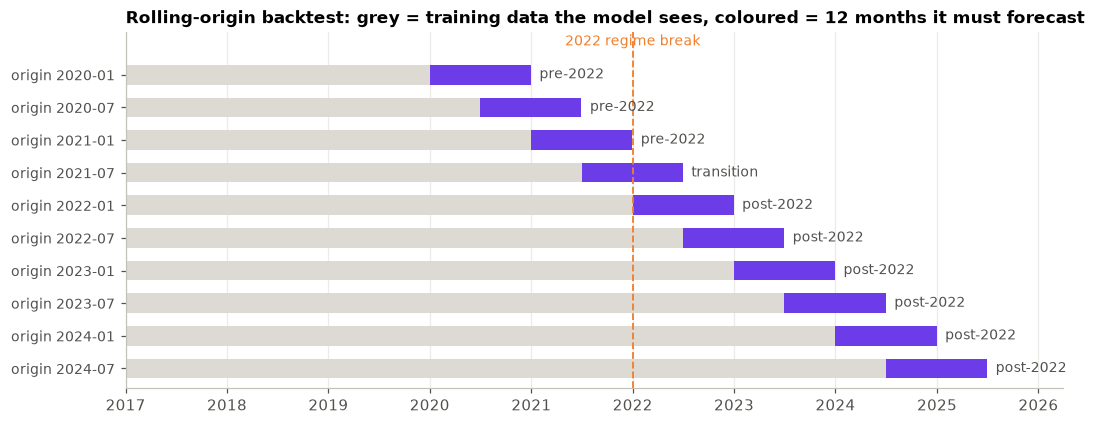

In [2]:
folds = (backtest.groupby("origin")
         .agg(test_end=("date", "max"), regime=("regime", "first"))
         .reset_index())
regime_en = {"до 2022": "pre-2022", "перехід": "transition", "після 2022": "post-2022"}
start = pd.Timestamp("2017-01-01")
fig, ax = plt.subplots(figsize=(11, 4.2))
for i, row in folds.iterrows():
    y = len(folds) - i
    ax.barh(y, row.origin - start, left=start, height=0.6, color="#dcdad3")
    ax.barh(y, row.test_end + pd.offsets.MonthEnd(0) - row.origin, left=row.origin,
            height=0.6, color=style.MODEL_COLORS["ETS"])
    ax.text(row.test_end + pd.Timedelta(days=60), y, regime_en[row.regime],
            va="center", fontsize=9, color=style.MUTED)
ax.axvline(bt.WAR, color=style.MODEL_COLORS["SARIMA"], linestyle="--", linewidth=1.2)
ax.text(bt.WAR, len(folds) + 0.9, "2022 regime break", color=style.MODEL_COLORS["SARIMA"], fontsize=9, ha="center")
ax.set_yticks(range(len(folds), 0, -1))
ax.set_yticklabels([f"origin {d:%Y-%m}" for d in folds.origin], fontsize=9)
ax.set_xlim(start, pd.Timestamp("2026-04-01"))
ax.set_ylim(0.4, len(folds) + 1.3)
ax.grid(axis="y", visible=False)
ax.set_title("Rolling-origin backtest: grey = training data the model sees, coloured = 12 months it must forecast")
style.save(fig, "validation_folds")
plt.show()

## 2. The Models

All seven are classical, non-ML methods. Each product is forecast separately, in its own published unit (UAH per kg, litre, 10 eggs, etc.).

| Group | Model | Forecast rule |
|---|---|---|
| **Naive benchmarks** | `naive` | Every future month = last observed price. |
| | `drift` | Last price plus the average monthly change over the training window. |
| | `seasonal_naive` | Each month = the same calendar month one year earlier. |
| | `snaive+yoy` | Seasonal naive plus last year's change in the average price level. |
| **First working models** | `STL+drift` | Robust STL on log prices; random walk with drift on the seasonally adjusted series, last seasonal cycle added back. |
| | `ETS` | Exponential smoothing on log prices: damped additive trend + additive 12-month seasonality. |
| | `SARIMA` | "Airline" model (0,1,1)(0,1,1)$_{12}$ on log prices. |

Log prices make seasonal swings multiplicative (a 30% summer drop stays 30% when the price level doubles) and keep back-transformed forecasts positive.

**Safeguard.** A forecast that is non-finite, non-positive, or outside 0.1×–10× of the last price is replaced by the naive forecast and logged in `results/fallbacks.csv` (Section 7). The corridor is wide on purpose: carrots legitimately move 3–6× within a year.

## 3. Metrics

| Metric | Formula | Unit | Use |
|---|---|---|---|
| MAE | $\frac{1}{n}\sum \lvert y_t-\hat y_t\rvert$ | UAH per product unit | Size of a typical miss; compare models **within** one product only. |
| RMSE | $\sqrt{\frac{1}{n}\sum (y_t-\hat y_t)^2}$ | UAH per product unit | Like MAE but punishes large misses harder. |
| **MASE** (primary) | $\dfrac{\lvert y_t-\hat y_t\rvert}{\frac{1}{T-12}\sum_{s=13}^{T}\lvert y_s-y_{s-12}\rvert}$ | none | Error divided by the in-sample error of a one-year-back guess, computed on the **training window only**. Scale-free, so it can be averaged across products. Below 1 = better than that in-sample yardstick. |
| sMAPE | $\dfrac{200\,\lvert y_t-\hat y_t\rvert}{\lvert y_t\rvert+\lvert\hat y_t\rvert}$ | % | Intuitive percentage; bounded at 200% and asymmetric, so secondary. |

Averages below are taken over products, origins, and horizons. **Win rate vs naive** = share of the 60 (product, origin) folds in which a model's 12-month MASE is lower than the naive forecast's.

## 4. Overall Leaderboard

In [3]:
fold_mase = backtest.groupby(["product", "origin", "model"])["ase"].mean().unstack()[MODELS]
leaderboard = pd.DataFrame({
    "MASE h1-12": backtest.groupby("model")["ase"].mean(),
    "MASE h1-3": backtest[backtest.h <= 3].groupby("model")["ase"].mean(),
    "sMAPE % h1-12": backtest.groupby("model")["smape"].mean(),
    "win rate vs naive": fold_mase.lt(fold_mase["naive"], axis=0).mean(),
    "win rate vs seasonal naive": fold_mase.lt(fold_mase["seasonal_naive"], axis=0).mean(),
}).loc[MODELS]
leaderboard.index.name = "model"
display(leaderboard.style.format({"MASE h1-12": "{:.2f}", "MASE h1-3": "{:.2f}", "sMAPE % h1-12": "{:.1f}",
                                  "win rate vs naive": "{:.0%}", "win rate vs seasonal naive": "{:.0%}"})
        .highlight_min(subset=["MASE h1-12", "MASE h1-3", "sMAPE % h1-12"], props="font-weight:bold"))

,MASE h1-12,MASE h1-3,sMAPE % h1-12,win rate vs naive,win rate vs seasonal naive
model,,,,,
naive,1.85,0.73,23.1,0%,72%
drift,1.80,0.73,22.9,63%,70%
seasonal_naive,2.29,1.65,27.9,28%,0%
snaive+yoy,2.27,1.38,28.9,30%,50%
STL+drift,2.05,1.22,25.9,50%,57%
ETS,1.71,0.69,21.9,65%,78%
SARIMA,1.81,0.71,21.0,57%,72%


## 5. Error by Forecast Horizon

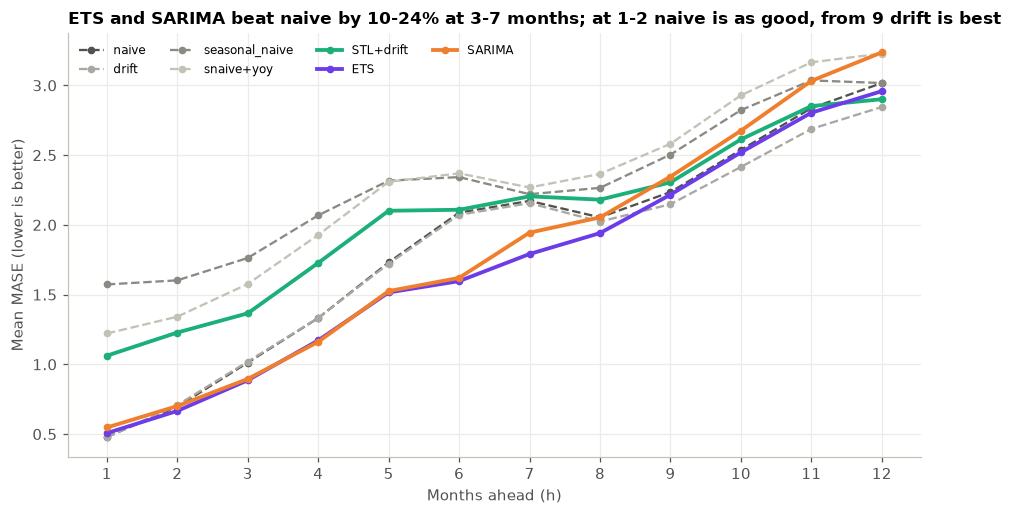

In [4]:
by_h = backtest.pivot_table(index="h", columns="model", values="ase")[MODELS]
fig, ax = plt.subplots(figsize=(10, 5))
for model in MODELS:
    benchmark = model in style.BENCHMARKS
    ax.plot(by_h.index, by_h[model], color=style.MODEL_COLORS[model],
            linewidth=1.5 if benchmark else 2.5, linestyle="--" if benchmark else "-",
            marker="o", markersize=4, label=model)
ax.set_xticks(range(1, 13))
ax.set(xlabel="Months ahead (h)", ylabel="Mean MASE (lower is better)")
ax.set_title("ETS and SARIMA beat naive by 10-24% at 3-7 months; at 1-2 naive is as good, from 9 drift is best")
ax.legend(ncol=4, fontsize=8, loc="upper left")
style.save(fig, "mase_by_horizon")
plt.show()

## 6. Results by Product and by Regime

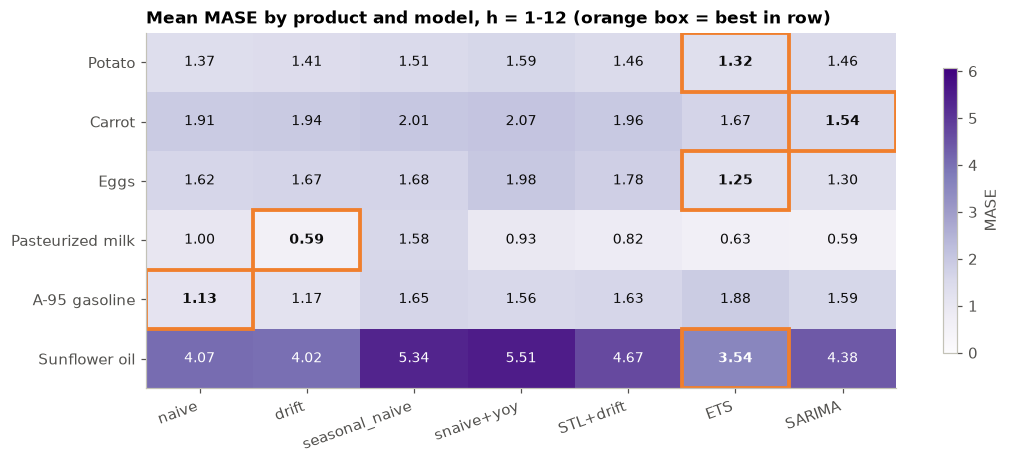

,best model,best MASE,naive MASE,best MAE (UAH),naive MAE (UAH)
product,,,,,
Potato,ETS,1.32,1.37,3.88,4.01
Carrot,SARIMA,1.54,1.91,9.04,11.29
Eggs,ETS,1.25,1.62,8.76,11.32
Pasteurized milk,drift,0.59,1.00,1.31,2.21
A-95 gasoline,naive,1.13,1.13,4.97,4.97
Sunflower oil,ETS,3.54,4.07,7.71,6.65


In [5]:
by_product = backtest.pivot_table(index="product", columns="model", values="ase").loc[PRODUCTS, MODELS]
fig, ax = plt.subplots(figsize=(11, 4.2))
image = ax.imshow(by_product.values, cmap="Purples", vmin=0, vmax=by_product.values.max() * 1.1, aspect="auto")
best = by_product.values.argmin(axis=1)
for i in range(by_product.shape[0]):
    for j in range(by_product.shape[1]):
        value = by_product.values[i, j]
        dark = value > by_product.values.max() * 0.6
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9,
                color="white" if dark else "#0b0b0b", fontweight="bold" if j == best[i] else "normal")
    ax.add_patch(plt.Rectangle((best[i] - 0.5, i - 0.5), 1, 1, fill=False, edgecolor="#f07f2d", linewidth=2.5))
ax.set_xticks(range(len(MODELS)))
ax.set_xticklabels(MODELS, rotation=20, ha="right")
ax.set_yticks(range(len(PRODUCTS)))
ax.set_yticklabels(PRODUCTS)
ax.grid(False)
ax.set_title("Mean MASE by product and model, h = 1-12 (orange box = best in row)")
fig.colorbar(image, ax=ax, label="MASE", shrink=0.8)
style.save(fig, "mase_by_product")
plt.show()

mae = backtest.pivot_table(index="product", columns="model", values="ae").loc[PRODUCTS, MODELS]
best_model = by_product.idxmin(axis=1)
display(pd.DataFrame({
    "best model": best_model,
    "best MASE": by_product.min(axis=1).round(2),
    "naive MASE": by_product["naive"].round(2),
    "best MAE (UAH)": [mae.loc[p, m] for p, m in best_model.items()],
    "naive MAE (UAH)": mae["naive"],
}).round(2))

In [6]:
fold_count = backtest.groupby("regime")["origin"].nunique()
by_regime = (backtest.pivot_table(index="regime", columns="model", values="ase")[MODELS]
             .rename(index=regime_en).loc[["pre-2022", "post-2022"]])
by_regime["folds"] = fold_count.rename(index=regime_en)
print("Mean MASE by regime, h = 1-12. Compare models within a row, not regimes with each other:")
print("each regime has a different MASE denominator and only 3 (pre) or 6 (post) origins.")
display(by_regime.style.format("{:.2f}", subset=MODELS).highlight_min(axis=1, subset=MODELS, props="font-weight:bold"))

Mean MASE by regime, h = 1-12. Compare models within a row, not regimes with each other:
each regime has a different MASE denominator and only 3 (pre) or 6 (post) origins.


model,naive,drift,seasonal_naive,snaive+yoy,STL+drift,ETS,SARIMA,folds
regime,,,,,,,,
pre-2022,2.62,2.60,3.06,3.33,2.92,1.99,2.57,3
post-2022,1.58,1.50,1.96,1.86,1.71,1.62,1.49,6


## 7. What the Forecasts Look Like

Forecasts from the last two origins (July 2023 and July 2024) against the published price. Shaded areas are the 12-month test windows.

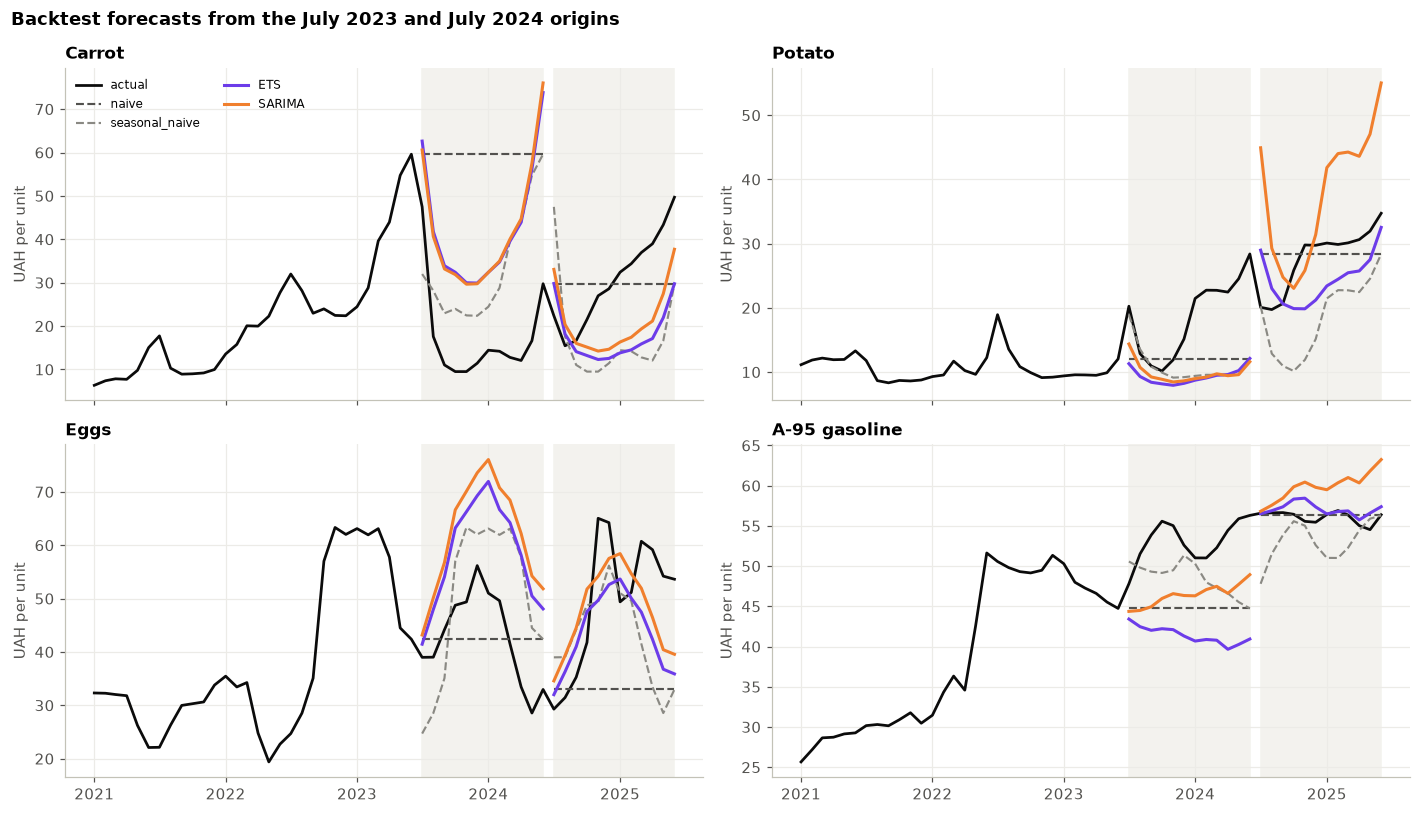

In [7]:
prices = bt.load_targets().rename(columns=style.LABELS)
show_products = ["Carrot", "Potato", "Eggs", "A-95 gasoline"]
show_models = ["naive", "seasonal_naive", "ETS", "SARIMA"]
show_origins = [pd.Timestamp("2023-07-01"), pd.Timestamp("2024-07-01")]
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True)
for ax, product in zip(axes.ravel(), show_products):
    history = prices.loc["2021-01-01":, product]
    ax.plot(history.index, history, color=style.ACTUAL_COLOR, linewidth=1.8, label="actual")
    for origin in show_origins:
        ax.axvspan(origin, origin + pd.DateOffset(months=11), color="#f3f2ee", zorder=0)
        window = backtest[(backtest["product"] == product) & (backtest.origin == origin)]
        for model in show_models:
            path = window[window.model == model].sort_values("date")
            ax.plot(path.date, path.yhat, color=style.MODEL_COLORS[model],
                    linestyle="--" if model in style.BENCHMARKS else "-",
                    linewidth=1.4 if model in style.BENCHMARKS else 2,
                    label=model if origin == show_origins[0] else None)
    ax.set_title(product)
    ax.set_ylabel("UAH per unit")
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[0, 0].legend(fontsize=8, ncol=2, loc="upper left")
fig.suptitle("Backtest forecasts from the July 2023 and July 2024 origins", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.tight_layout()
style.save(fig, "forecasts_vs_actual")
plt.show()

## 8. Reliability Checks: SARIMA Convergence, Fallbacks, STL Behaviour

In [8]:
convergence["product"] = convergence["good"].map(style.LABELS)
print(f"SARIMA optimiser converged in {convergence.converged.sum()} of {len(convergence)} fits.")
display(convergence.groupby("product")["converged"].agg(fits="count", converged="sum")
        .assign(not_converged=lambda d: d.fits - d.converged))

sarima = backtest[backtest.model == "SARIMA"]
converged_folds = convergence.loc[convergence.converged, ["good", "origin"]]
on_converged = backtest.merge(converged_folds, on=["good", "origin"])
print("Mean MASE h1-12, SARIMA on all folds vs only folds where it converged:",
      f"{sarima.ase.mean():.2f} vs {sarima[sarima.sarima_converged == 1].ase.mean():.2f}")
print("All models restricted to the converged folds (fair comparison):")
display(on_converged.groupby("model")["ase"].mean().loc[MODELS].round(2).to_frame("MASE h1-12").T)

fallbacks["product"] = fallbacks["good"].map(style.LABELS)
print(f"Forecasts replaced by naive: {len(fallbacks)} of {backtest.groupby(['good', 'model', 'origin']).ngroups}")
display(fallbacks[["product", "model", "origin", "reason"]])

SARIMA optimiser converged in 48 of 60 fits.


,fits,converged,not_converged
product,,,
A-95 gasoline,10,9,1
Carrot,10,10,0
Eggs,10,9,1
Pasteurized milk,10,5,5
Potato,10,9,1
Sunflower oil,10,6,4


Mean MASE h1-12, SARIMA on all folds vs only folds where it converged: 1.81 vs 1.69
All models restricted to the converged folds (fair comparison):


model,naive,drift,seasonal_naive,snaive+yoy,STL+drift,ETS,SARIMA
MASE h1-12,1.74,1.71,2.19,2.16,1.91,1.59,1.69


Forecasts replaced by naive: 2 of 420


,product,model,origin,reason
0,Carrot,snaive+yoy,2020-07-01,implausible forecast (x-0.05..x0.77 of last pr...
1,Carrot,snaive+yoy,2024-07-01,implausible forecast (x-0.23..x1.04 of last pr...


In [9]:
# Why STL+drift loses even at h = 1: the flexible STL seasonal term absorbs one-off shocks.
eggs = backtest[(backtest["product"] == "Eggs") & (backtest.origin == "2024-01-01") & (backtest.h == 1)]
display(eggs.set_index("model").loc[["naive", "STL+drift", "ETS", "SARIMA"], ["date", "y", "yhat"]]
        .rename(columns={"y": "actual price", "yhat": "forecast"}).round(2))

/var/folders/lm/1j4d75t5239810k151m0ylm00000gn/T/ipykernel_47246/1144714263.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .rename(columns={"y": "actual price", "yhat": "forecast"}).round(2))


,date,actual price,forecast
model,,,
naive,2024-01-01,51.02,56.18
STL+drift,2024-01-01,51.02,77.54
ETS,2024-01-01,51.02,58.41
SARIMA,2024-01-01,51.02,60.47


`STL+drift` is the weakest fitted model even one month ahead. Its forecast is *last seasonally-adjusted value + seasonal term of the target month*. Robust STL lets the seasonal term evolve, so the egg-price spike of winter 2022/23 was absorbed into the "January" seasonal effect; in January 2024 the model therefore predicted a 38% jump that never happened. ETS updates its seasonal terms with smoothing and does not show this failure. This follows from how the model forecasts (last seasonally adjusted value + drift + the target month's seasonal term); it is a model limitation, not a code bug.

## 9. Final Holdout: July–September 2025

Every model is refitted on all 102 months (2017-01 to 2025-06) and asked for 3 months ahead. These months were published after the data snapshot and were never used for any modelling choice. MASE uses the same training-window scale definition as the backtest. One origin and three months is a small sample, so this is a sanity check rather than a second leaderboard.

In [10]:
holdout_file = ROOT / "data" / "processed" / "avg_prices_holdout.csv"
if not holdout_file.exists():
    raise FileNotFoundError("Run src/data/prepare_holdout.py to extract July-September 2025 first.")
holdout = pd.read_csv(holdout_file, parse_dates=["date"])
holdout = (holdout[holdout.region == "Україна"].pivot(index="date", columns="good", values="value")[bt.SERIES])
full = bt.load_targets()
H_OUT = len(holdout)
rows, sarima_converged = [], {}
for good in bt.SERIES:
    train = full[good]
    scale = np.mean(np.abs(train.values[bt.M:] - train.values[:-bt.M]))
    for model, forecast_fn in bt.MODELS.items():
        with warnings.catch_warnings():  # convergence is read explicitly below, not from warnings
            warnings.simplefilter("ignore")
            forecast = bt.guarded_forecast(forecast_fn, train, H_OUT)
        if model == "SARIMA":
            sarima_converged[style.LABELS[good]] = bt.f_sarima.converged
        for h in range(H_OUT):
            actual = holdout[good].iloc[h]
            rows.append((style.LABELS[good], model, holdout.index[h], actual, forecast[h],
                         abs(actual - forecast[h]) / scale))
final = pd.DataFrame(rows, columns=["product", "model", "date", "actual", "forecast", "ase"])
print("SARIMA converged on the full history:", sarima_converged)
final_table = final.pivot_table(index="product", columns="model", values="ase").loc[PRODUCTS, MODELS]
final_table.loc["Mean (6 products)"] = final_table.mean()
display(final_table.style.format("{:.2f}").highlight_min(axis=1, props="font-weight:bold"))

SARIMA converged on the full history: {'Potato': True, 'Carrot': True, 'Eggs': True, 'Pasteurized milk': True, 'A-95 gasoline': True, 'Sunflower oil': True}


model,naive,drift,seasonal_naive,snaive+yoy,STL+drift,ETS,SARIMA
product,,,,,,,
Potato,3.19,3.33,0.72,1.90,2.85,1.79,1.80
Carrot,2.87,2.95,0.44,1.09,1.42,1.13,1.24
Eggs,0.12,0.08,2.29,1.61,1.07,0.53,0.57
Pasteurized milk,0.09,0.10,2.41,0.42,0.67,0.07,0.12
A-95 gasoline,0.41,0.31,0.37,0.12,0.26,0.26,0.10
Sunflower oil,0.16,0.06,2.57,1.07,0.89,0.26,0.18
Mean (6 products),1.14,1.14,1.47,1.03,1.19,0.68,0.67


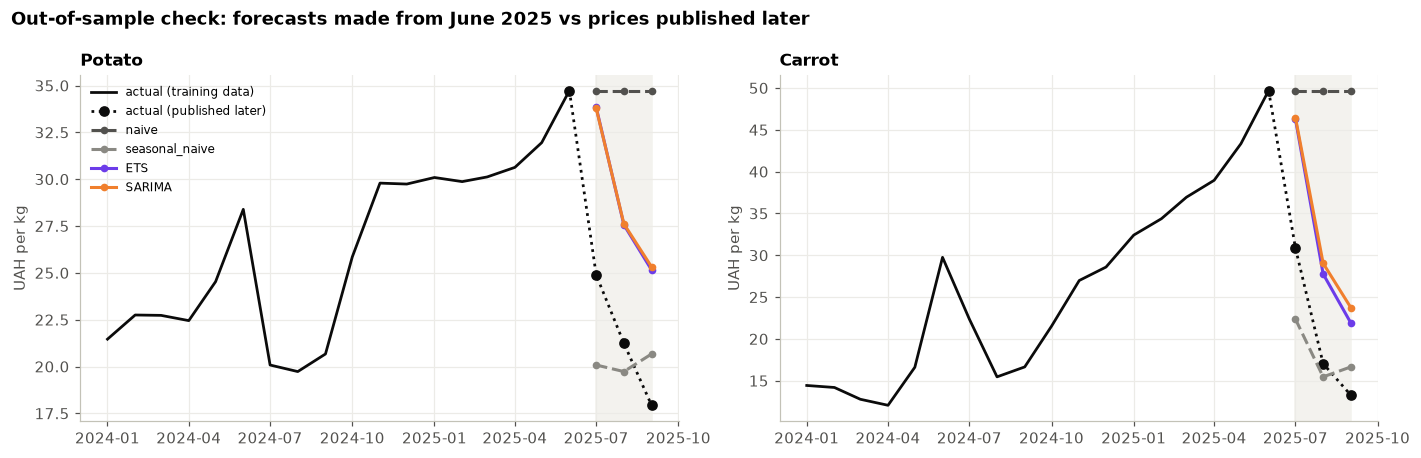

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, product in zip(axes, ["Potato", "Carrot"]):
    history = prices.loc["2024-01-01":, product]
    actual = pd.concat([history.iloc[-1:], holdout.rename(columns=style.LABELS)[product]])
    ax.plot(history.index, history, color=style.ACTUAL_COLOR, linewidth=1.8, label="actual (training data)")
    ax.plot(actual.index, actual, color=style.ACTUAL_COLOR, linewidth=1.8, linestyle=":", marker="o",
            label="actual (published later)")
    ax.axvspan(actual.index[1], actual.index[-1], color="#f3f2ee", zorder=0)
    for model in ["naive", "seasonal_naive", "ETS", "SARIMA"]:
        path = final[(final["product"] == product) & (final.model == model)]
        ax.plot(path.date, path.forecast, color=style.MODEL_COLORS[model], marker="o", markersize=4,
                linestyle="--" if model in style.BENCHMARKS else "-", label=model)
    ax.set_title(product)
    ax.set_ylabel("UAH per kg")
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
axes[0].legend(fontsize=8)
fig.suptitle("Out-of-sample check: forecasts made from June 2025 vs prices published later",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
style.save(fig, "holdout_2025")
plt.show()

## 10. Findings

- **The naive forecast is hard to beat.** Over 12 months the best model (ETS, MASE 1.71) is only 7% better than "tomorrow = today" (1.85), and beats it in 65% of folds. One to three months ahead naive, ETS, and SARIMA are nearly tied (0.69–0.73).
- **Seasonality only pays when it is modelled with care.** The pure seasonal naive is the *worst* model (2.29): the price level moved so much (inflation, the 2022 shock) that last year's value is a poor guess. ETS and SARIMA combine level and seasonality and are the best fitted models. They beat naive by 10–24% at 3–7 months ahead (most at 6 months); at 1–2 months naive and drift are as good or better, and from 9 months drift is best.
- **Per product the winner differs.** ETS wins for potato, eggs, and sunflower oil; SARIMA for carrot; drift for milk (smooth trend); naive for gasoline (shock-driven, almost no seasonality).
- **The ranking shifts with the regime.** Before 2022 ETS is clearly best (1.99 vs 2.57-3.33 for the rest); after 2022 SARIMA (1.49), drift (1.50), and naive (1.58) are almost tied with ETS (1.62). With 3 and 6 origins per regime, these differences are indicative only.
- **Fitted models have failure modes to watch.** SARIMA failed to converge in 12 of 60 fits (mostly milk and sunflower oil); STL+drift transfers one-off shocks into its seasonal term. Two seasonal-naive+YoY forecasts for carrots were replaced by naive.
- **The out-of-sample check agrees, for a specific reason.** On July–September 2025, ETS and SARIMA have the lowest mean MASE (0.68 and 0.67, naive 1.14) because they are never far off. Seasonal naive was best for potato and carrot (it fully expected the post-harvest fall) but worst for eggs, milk, and oil; the trend benchmarks (naive, drift) were near-perfect on eggs and oil but worst on potato and carrot. The fitted models are the robust compromise across products.

**Carried forward:** ETS and SARIMA as the working models, naive as the benchmark every future model must beat, MASE as the primary metric, and the rolling-origin design unchanged.